In [43]:
import numpy as np
import pandas as pd

In [ ]:
'''
stage_1_rank1:
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'
##################
stage_2_rank1:
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'
#################
stage_3_rank1:
graph_path_1 = './result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'


'''

## stage1

In [43]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage1/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage1/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name #.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


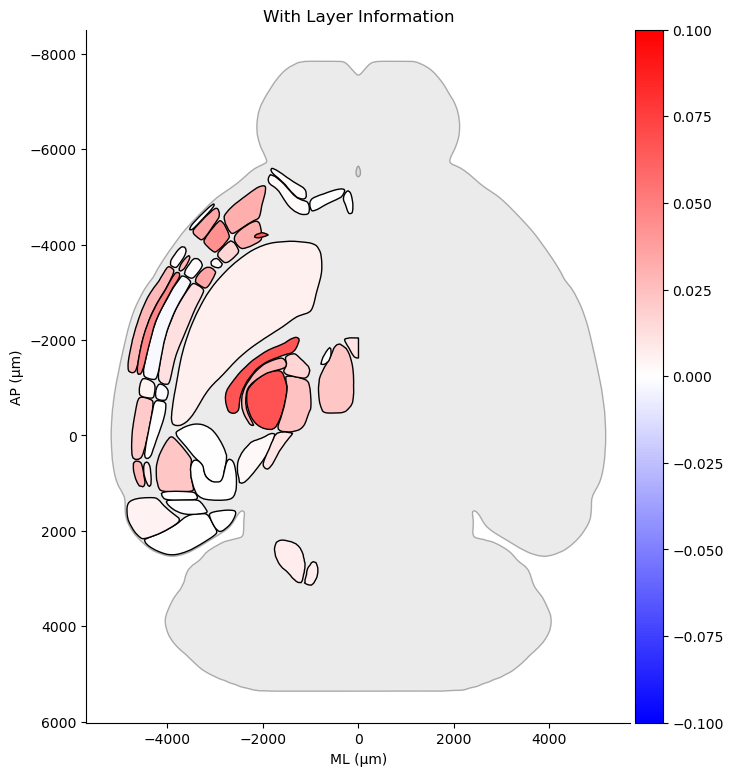

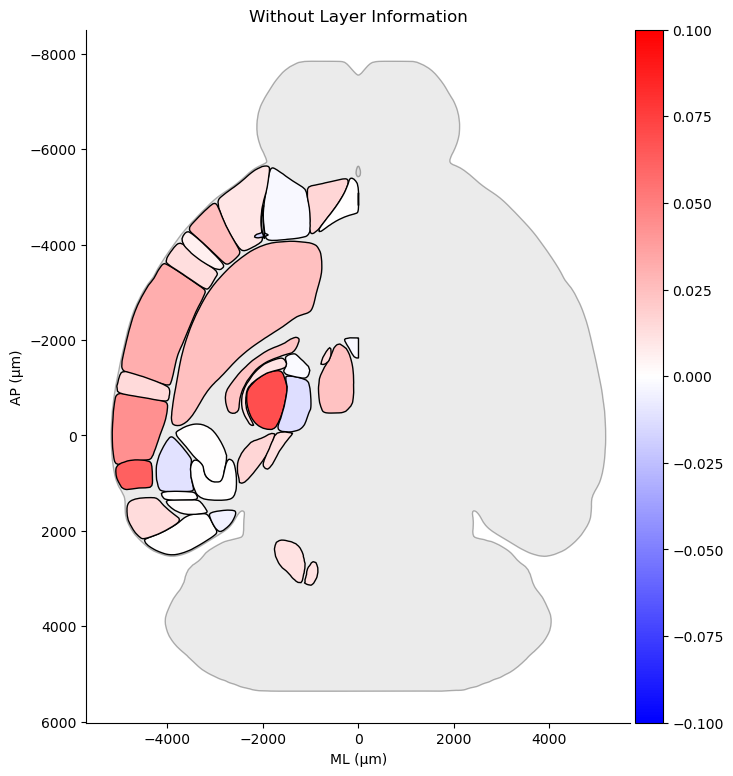

In [44]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.271, p = 1.365e-02, MAE = 0.0118


/tmp/ipykernel_3562360/517763304.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


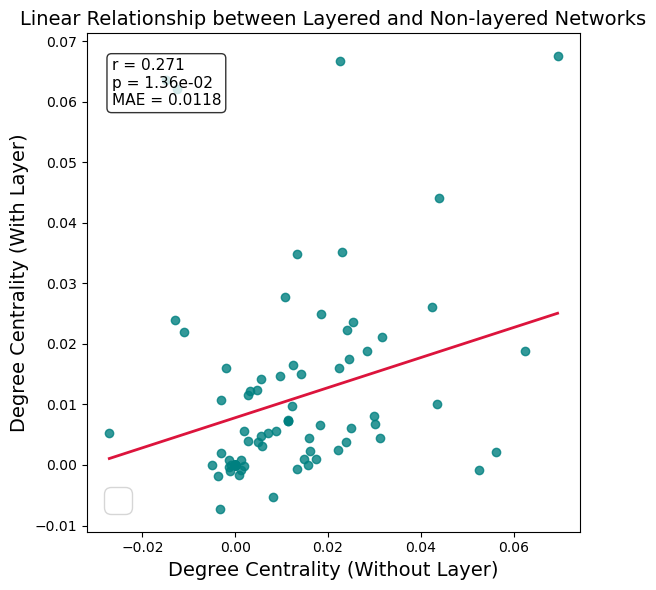

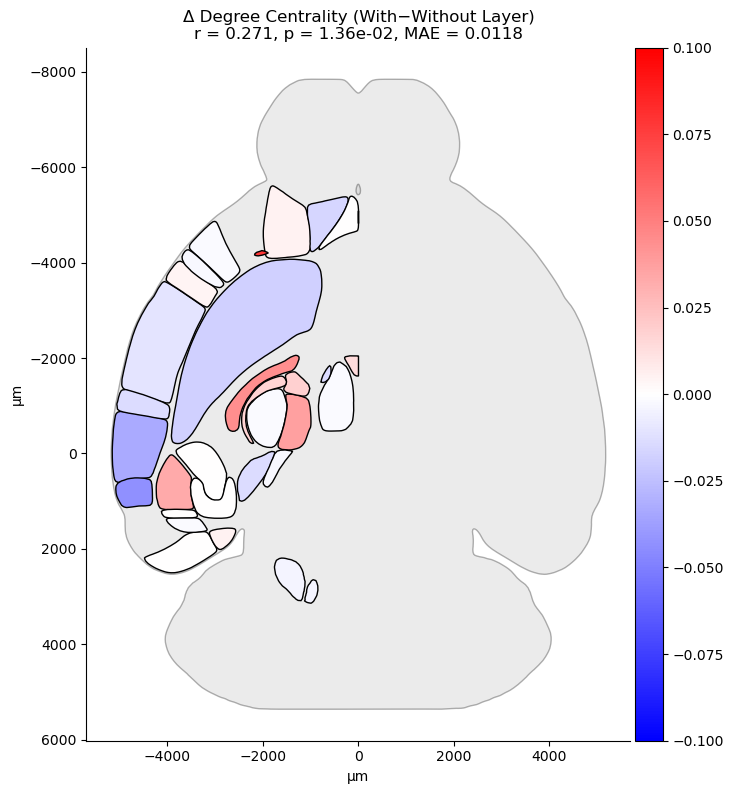

In [45]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage1.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

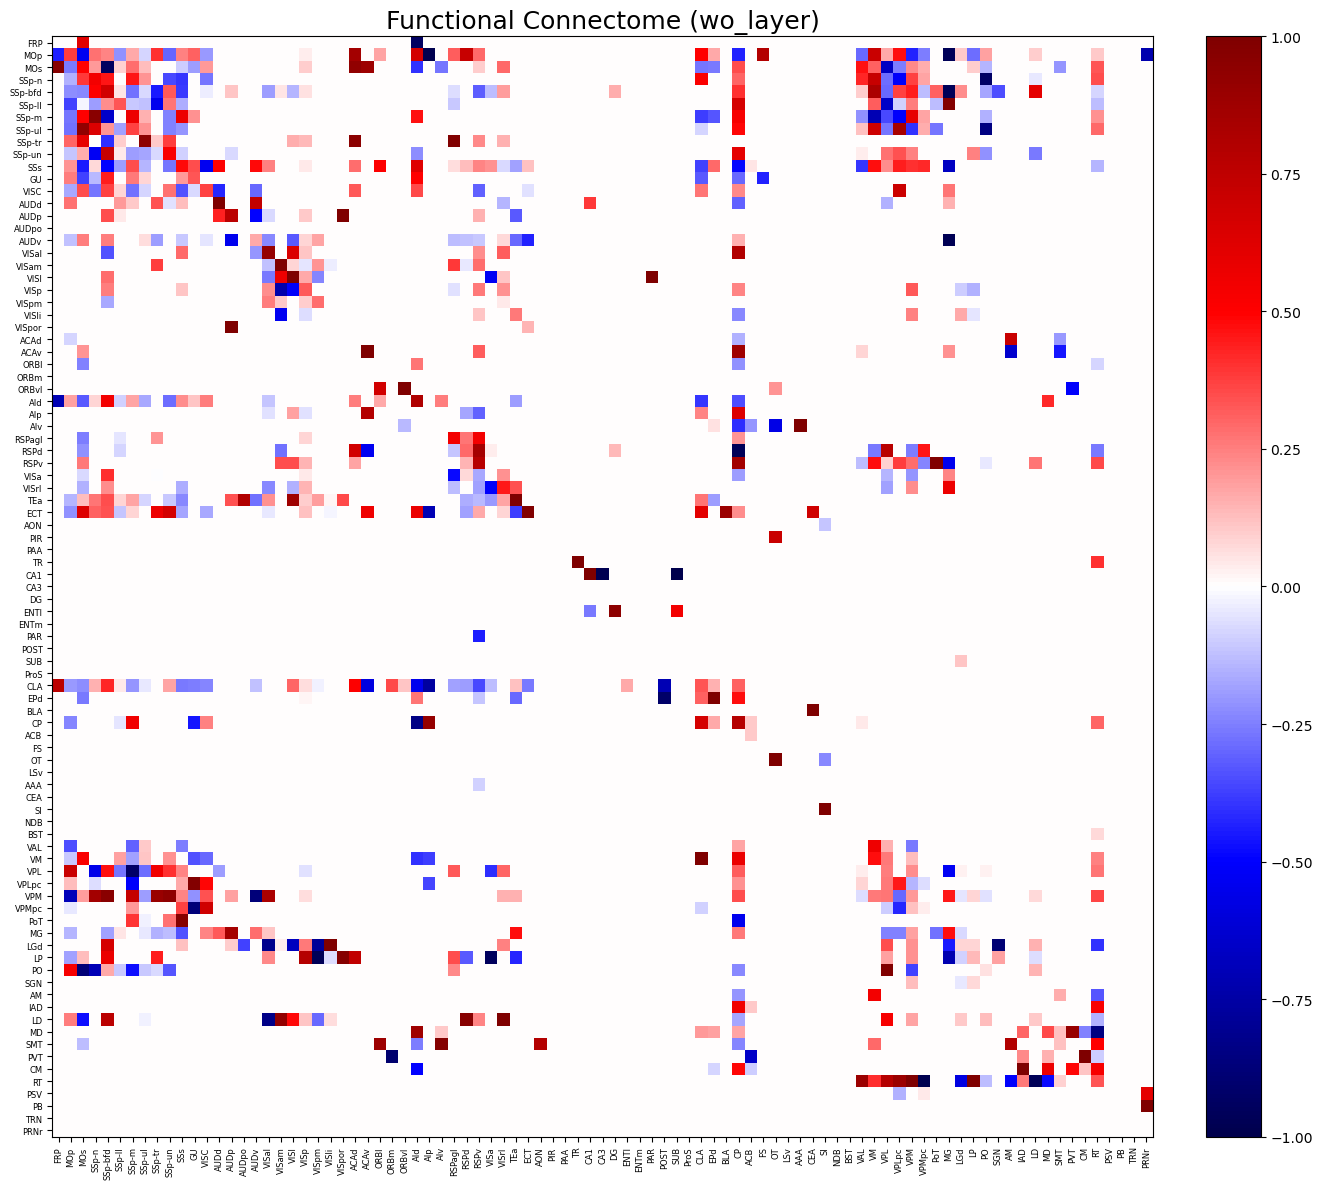

In [91]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage1.jpg", format="jpg", dpi=300)
plt.show()


## stage2

In [40]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage2/tuning/bs64_dp0.6_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage2/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)

#print("✅ 组1（含分层）主要脑区中心性：")
#print(mean_dc_1.head())
#print("\n✅ 组2（不含分层）主要脑区中心性：")
#print(mean_dc_2.head())


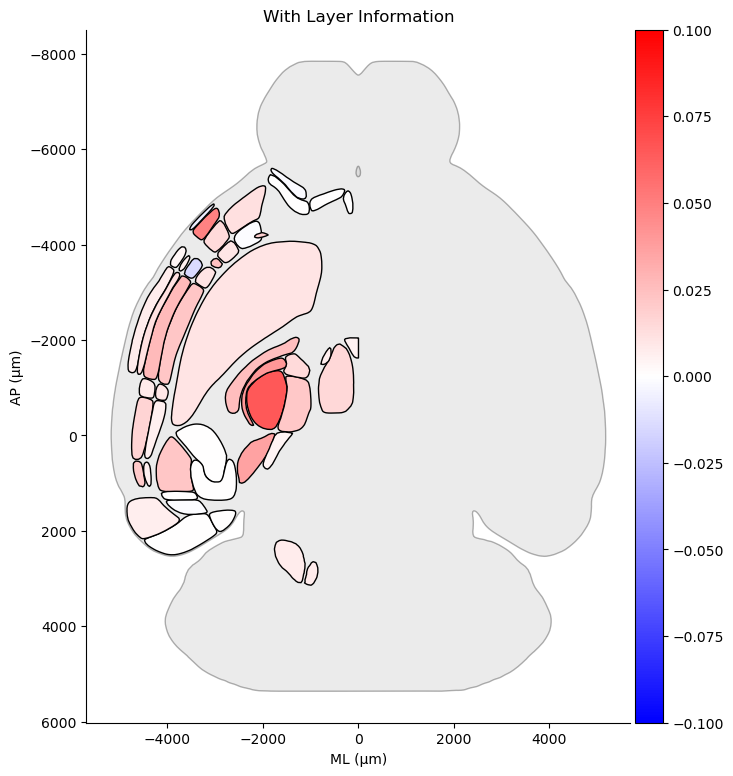

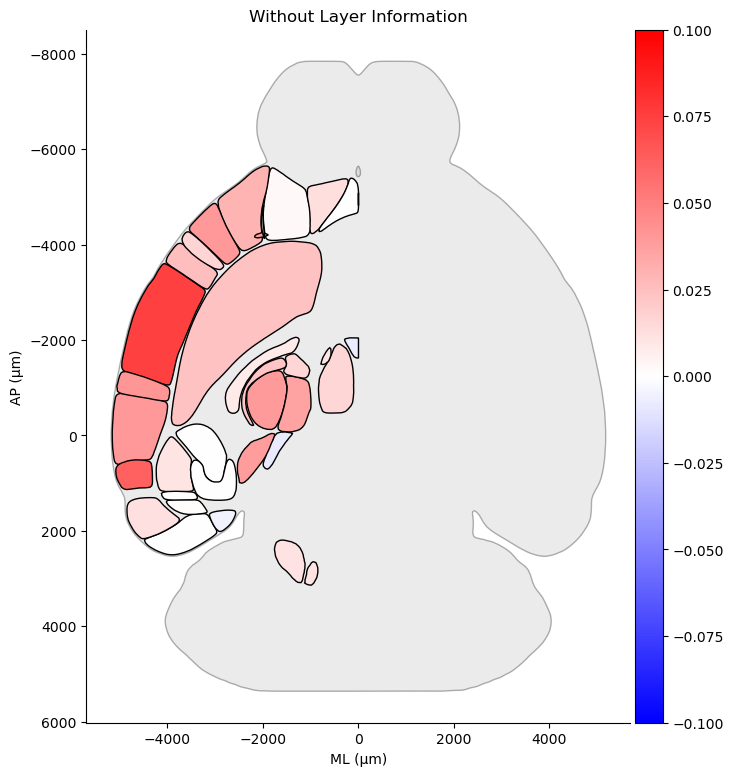

In [41]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.535, p = 2.265e-07, MAE = 0.0131


/tmp/ipykernel_3562360/1269202713.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


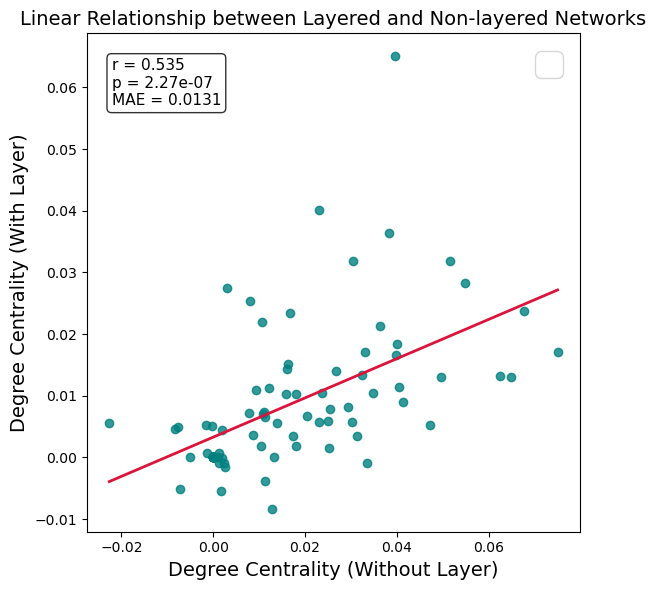

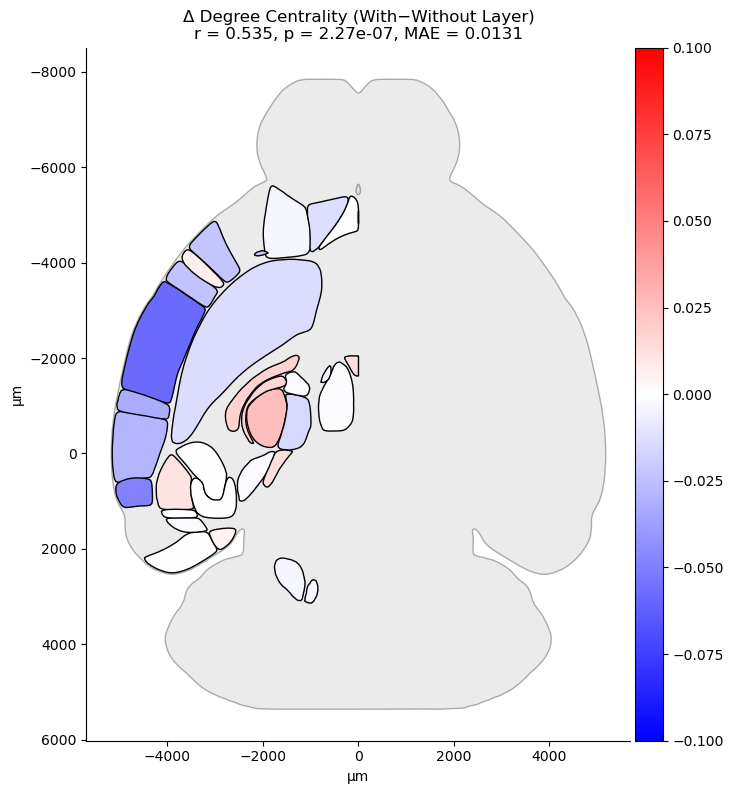

In [42]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage2.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

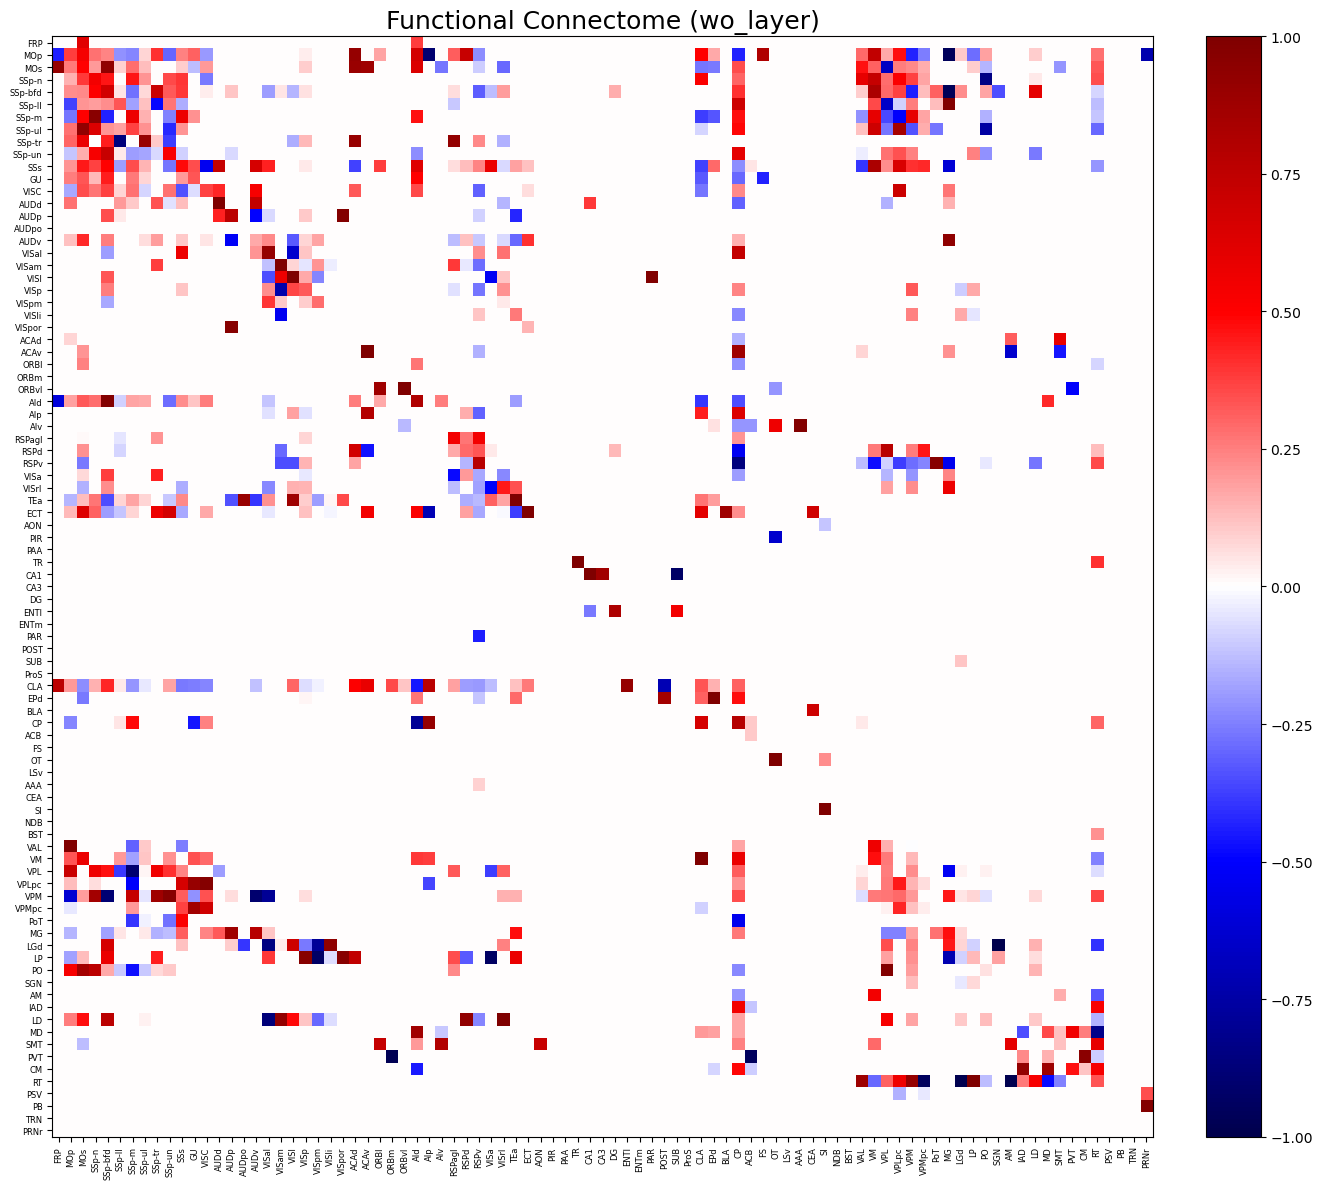

In [94]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams

rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage2.jpg", format="jpg", dpi=300)
plt.show()


## stage3

In [27]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh
import matplotlib.pyplot as plt

# === 1️⃣ 设定路径 ===
graph_path_1 = './result/w_layer/stage3/tuning/bs32_dp0.8_sw0.7/dynamic_full_graphs.npy'
label_path_1 = './result/w_layer/stage3/df_scaled.csv'

graph_path_2 = './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

# === 2️⃣ 定义函数：计算平均归一化度中心性 ===
def compute_mean_degree_centrality(graph_path, label_path):
    graphs = np.load(graph_path)  # (T, N, N)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].values  # 第一列为标签

    degree_centrality = {label: [] for label in labels}

    for t in range(graphs.shape[0]):
        adj = graphs[t]
        degrees = np.sum(adj, axis=1)
        norm_degrees = degrees / (adj.shape[0] - 1)
        for i, region in enumerate(labels):
            degree_centrality[region].append(norm_degrees[i])

    dc_df = pd.DataFrame(degree_centrality)
    mean_dc = dc_df.mean()

    # --- 合并带“-”的子区（取平均） ---
    merged = {}
    for name, val in mean_dc.items():
        if '-' in name:
            key = name#.split('-')[0]
            merged.setdefault(key, []).append(val)
        else:
            merged.setdefault(name, []).append(val)
    merged_dc = pd.Series({k: pd.Series(v).mean() for k, v in merged.items()})
    return merged_dc


# === 3️⃣ 分别计算两组结果 ===
mean_dc_1 = compute_mean_degree_centrality(graph_path_1, label_path_1)
mean_dc_2 = compute_mean_degree_centrality(graph_path_2, label_path_2)


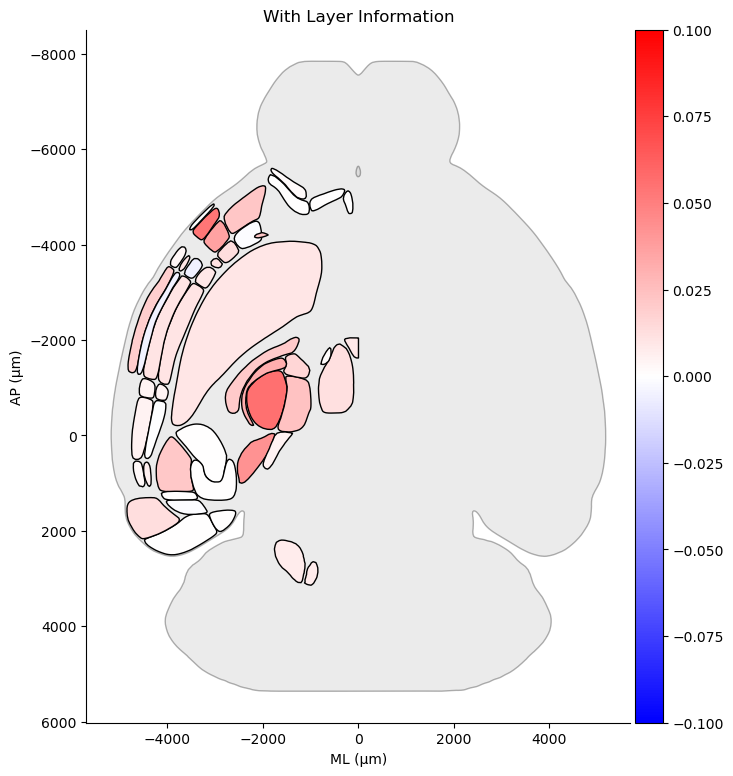

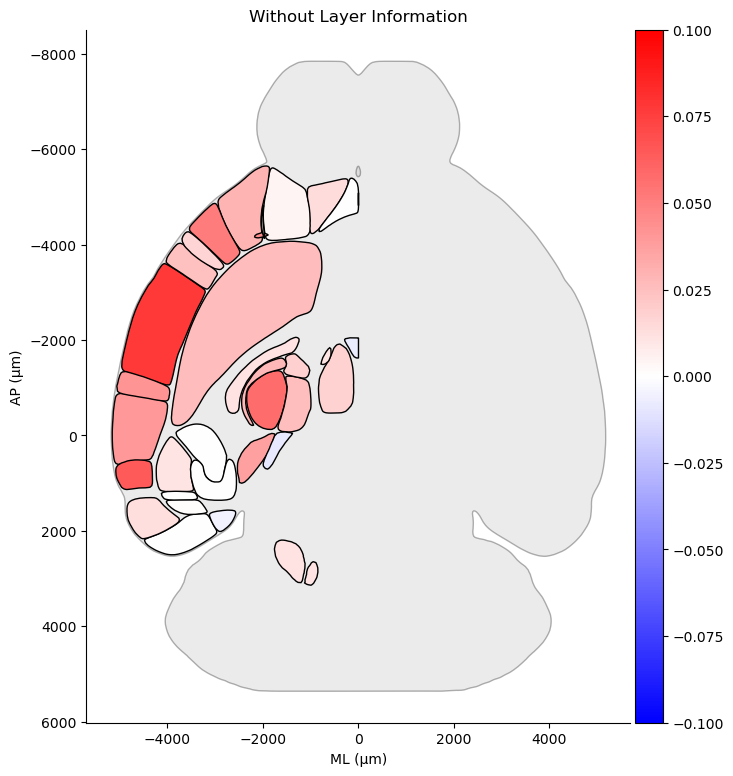

In [28]:
import numpy as np
import pandas as pd
import brainglobe_heatmap as bgh

# 假设 mean_dc_1 和 mean_dc_2 已计算完毕
values1 = mean_dc_1.to_dict()
values2 = mean_dc_2.to_dict()

vmin = -0.1
vmax = 0.1

# 第一张：含分层信息
fig = bgh.Heatmap(
    values=values1,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="With Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')

# 第二张：不含分层信息
fig = bgh.Heatmap(
    values=values2,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    vmin=vmin,
    vmax=vmax,
    cmap="bwr",
    format="2D",
    atlas_name="allen_mouse_25um",
    title="Without Layer Information"
).show(xlabel='ML (μm)', ylabel='AP (μm)')


r = 0.493, p = 2.539e-06, MAE = 0.0129


/tmp/ipykernel_3562360/1497357260.py:53: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(fontsize=25)


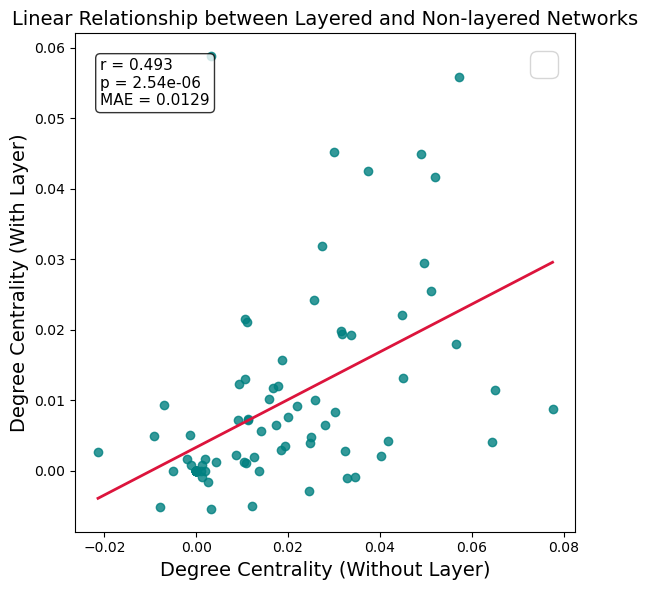

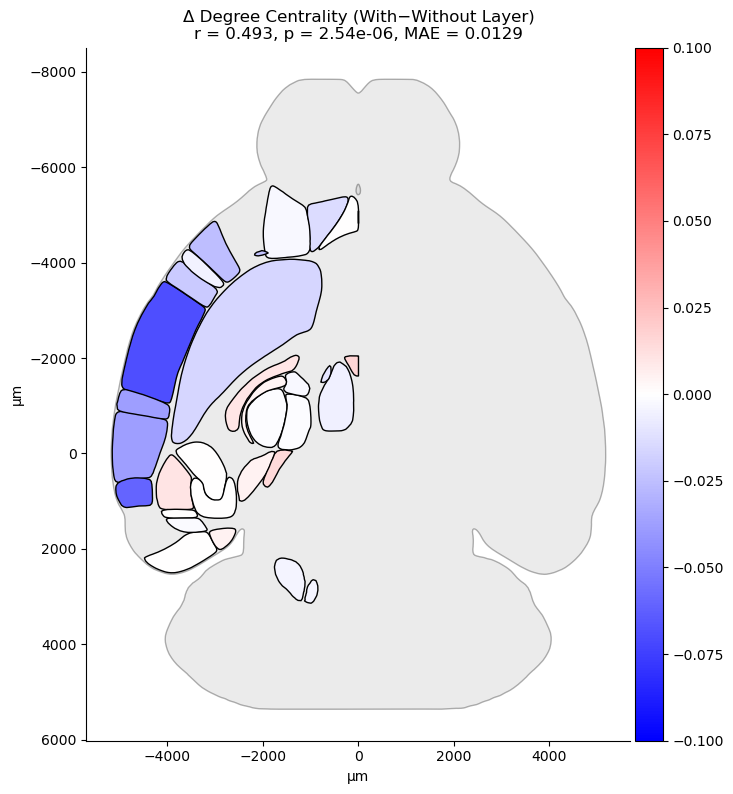

In [38]:
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import brainglobe_heatmap as bgh
from scipy.stats import linregress

w_layer = mean_dc_1.copy()
wo_layer = mean_dc_2.copy()


def get_base_region(name):
    df = pd.read_csv("./data/region_map.csv", sep="\t")
    region_dict = dict(zip(df.iloc[:,0], df.iloc[:,1]))
    return region_dict.get(name, name)

grouped = {}
for region, val in w_layer.items():
    base = get_base_region(region)
    grouped.setdefault(base, []).append(val)

layer_mean = {base: np.nanmean(vals) for base, vals in grouped.items()}
layer_mean = pd.Series(layer_mean)

common_regions = sorted(set(layer_mean.index) & set(wo_layer.index))
aligned_w = layer_mean[common_regions]
aligned_wo = wo_layer[common_regions]


r, p = pearsonr(aligned_w, aligned_wo)
mae = np.mean(np.abs(aligned_w - aligned_wo))
print(f"r = {r:.3f}, p = {p:.3e}, MAE = {mae:.4f}")

plt.figure(figsize=(6,6))
plt.scatter(aligned_wo, aligned_w, color="teal", alpha=0.8, label="")

slope, intercept, r_val, p_val, stderr = linregress(aligned_wo, aligned_w)

x_fit = np.linspace(aligned_wo.min(), aligned_wo.max(), 100)
y_fit = slope * x_fit + intercept
plt.plot(x_fit, y_fit, color="crimson", linewidth=2, label="")

plt.xlabel("Degree Centrality (Without Layer)", fontsize=14)
plt.ylabel("Degree Centrality (With Layer)", fontsize=14)
plt.title("Linear Relationship between Layered and Non-layered Networks", fontsize=14)

text_str = f"r = {r:.3f}\np = {p:.2e}\nMAE = {mae:.4f}"
plt.text(0.05, 0.95, text_str, transform=plt.gca().transAxes,
         fontsize=11, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))

plt.legend(fontsize=25)
plt.grid(alpha=0)
plt.tight_layout()
plt.savefig("./result/fig/scatter_with_vs_without_layer_stage3.png", dpi=300, bbox_inches="tight")

plt.show()



diff_map = (aligned_w - aligned_wo).to_dict()

fig = bgh.Heatmap(
    values=diff_map,
    hemisphere="left",
    position=4000,
    orientation="horizontal",
    thickness=1500,
    format="2D",
    vmin=-0.1,
    vmax=0.1,
    cmap="bwr",
    atlas_name="allen_mouse_25um",
    title=f"Δ Degree Centrality (With−Without Layer)\n"
          f"r = {r:.3f}, p = {p:.2e}, MAE = {mae:.4f}"
).plot(size=(400,300), axes=False)

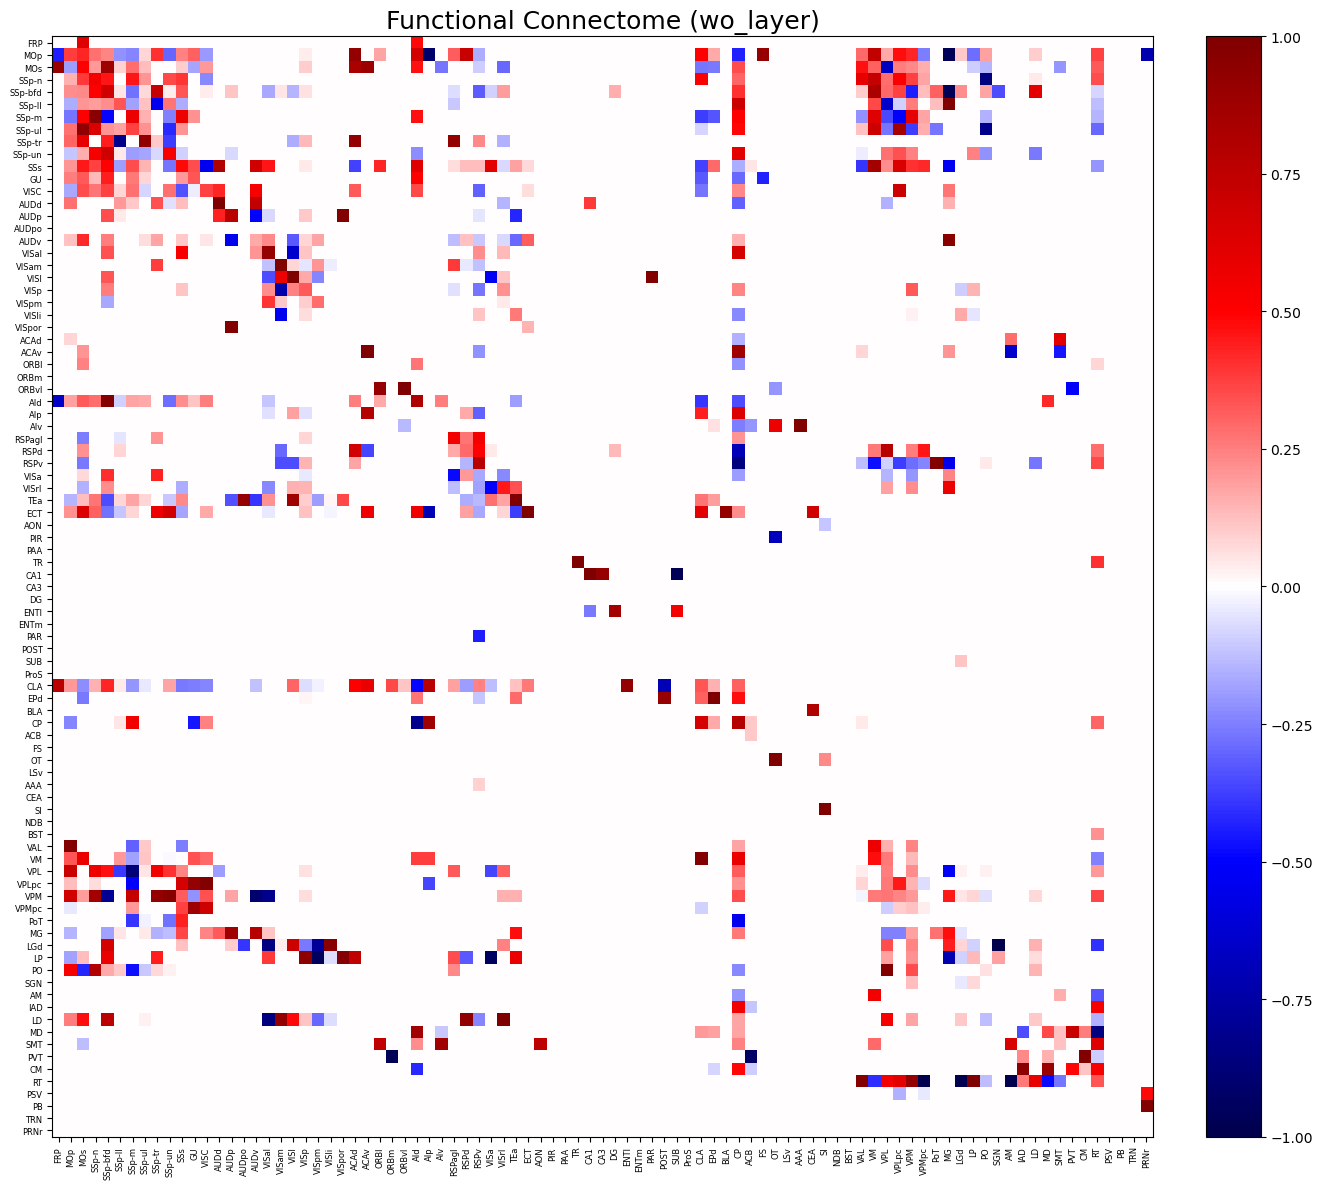

In [96]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import rcParams
rcParams['font.family'] = 'DejaVu Sans'
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42

graphs = np.load(graph_path_2)
df = pd.read_csv(label_path_2)
labels = df.iloc[:, 0].astype(str).str.strip().values

adj_matrix = graphs.mean(axis=0)

plt.figure(figsize=(14, 12))

im = plt.imshow(adj_matrix, cmap="seismic", aspect="equal", vmin=-1, vmax=1)

plt.title("Functional Connectome (wo_layer)", fontsize=18)

plt.xticks(ticks=np.arange(len(labels)), labels=labels, rotation=90, fontsize=6)
plt.yticks(ticks=np.arange(len(labels)), labels=labels, fontsize=6)

cbar = plt.colorbar(im, fraction=0.046, pad=0.04)
cbar.ax.tick_params(labelsize=10)

plt.tight_layout()

plt.savefig("./result/fig/functional_connectome_wo_layer_stage3.jpg", format="jpg", dpi=300)
plt.show()


## Three stages similarity calculation

In [98]:
import numpy as np
import pandas as pd

def load_mean_adj(graph_path, label_path):
    graphs = np.load(graph_path)
    adj = graphs.mean(axis=0)
    df = pd.read_csv(label_path)
    labels = df.iloc[:, 0].astype(str).str.strip().values
    return adj, labels

# paths
stage1_graph_path_2 = './result/wo_layer/stage1/tuning/bs8_dp0.1_sw1.0/dynamic_full_graphs.npy'
stage1_label_path_2 = './result/wo_layer/stage1/df_scaled.csv'

stage2_graph_path_2 = './result/wo_layer/stage2/tuning/bs64_dp0.8_sw0.7/dynamic_full_graphs.npy'
stage2_label_path_2 = './result/wo_layer/stage2/df_scaled.csv'

stage3_graph_path_2 = './result/wo_layer/stage3/tuning/bs64_dp0.8_sw1.0/dynamic_full_graphs.npy'
stage3_label_path_2 = './result/wo_layer/stage3/df_scaled.csv'

A1, L1 = load_mean_adj(stage1_graph_path_2, stage1_label_path_2)
A2, L2 = load_mean_adj(stage2_graph_path_2, stage2_label_path_2)
A3, L3 = load_mean_adj(stage3_graph_path_2, stage3_label_path_2)

# find intersection regions
common = sorted(list(set(L1) & set(L2) & set(L3)))

def reorder(adj, labels, common):
    idx = [np.where(labels == c)[0][0] for c in common]
    return adj[np.ix_(idx, idx)]

A1c = reorder(A1, L1, common)
A2c = reorder(A2, L2, common)
A3c = reorder(A3, L3, common)

# --- YOUR CONSISTENCY DEFINITION ---
def consistency(A, B):
    diff = np.abs(A - B)
    triu = np.triu_indices(diff.shape[0], k=1)
    mean_diff = diff[triu].mean()
    return 1 - mean_diff / 2

c12 = consistency(A1c, A2c)
c13 = consistency(A1c, A3c)
c23 = consistency(A2c, A3c)

print("Intersection brain regions:", len(common))
print("Consistency (Stage1 vs Stage2):", round(c12, 4))
print("Consistency (Stage1 vs Stage3):", round(c13, 4))
print("Consistency (Stage2 vs Stage3):", round(c23, 4))


Intersection brain regions: 89
Consistency (Stage1 vs Stage2): 0.9916
Consistency (Stage1 vs Stage3): 0.9913
Consistency (Stage2 vs Stage3): 0.9991
